# Topic Modeling Pemberitaan Karhutla Period Agustus-October 2026

## 1. Latar Belakang

Pemberitaan kebakaran hutan dan lahan (karhutla) belakang menjadi issue hangat dan dampaknya sudah dirasakan, serta ramai dibicarakan oleh negara tetangga. Pemberitaan ini mencakup pemadaman, kesehatan warga, kualitas udara, dan tanggung jawab pihak terkait. Analisis ini menggunakan pemodelan topik untuk mengidentifikasi isu yang berulang dalam ribuan artikel dan memilih berita yang perlu ditelaah lebih lanjut.

BKPK Kementerian Kesehatan membahas perhatian media terhadap karhutla dalam publikasi *Karhutla di Indonesia: Saat Asap Datang, Kita Siap*. 
Percakapan di media sosial turut menjadi konteks analisis, tetapi data yang digunakan hanya mencakup artikel berita. Karena itu, analisis ini tidak mengukur perhatian pengguna media sosial. Kementerian Kesehatan mengaitkan paparan asap karhutla dengan gangguan kesehatan, termasuk infeksi saluran pernapasan akut (ISPA), serta menekankan perlindungan kelompok rentan. Di tingkat regional, ASEAN membahas pengendalian pencemaran asap lintas batas melalui kerja sama antarnegara. Kedua konteks ini menjadi dasar untuk menelaah isu kesehatan dan dampak lintas negara dalam pemberitaan.

## 2. Rumusan Masalah
Adapun rumusan masalah yang diangkat adalah sebagai berikut:
1. Isu apa yang paling banyak muncul dalam pemberitaan karhutla?
2. Bagaimana perbedaan pengelompokan isu berdasarkan pemodelan topik NMF dan LDA?
3. Kelompok topik mana yang memiliki tema jelas dan mana yang masih memerlukan pemeriksaan isi berita?

Analisis ini bertujuan memetakan isu untuk membantu pemantauan berita. Kami menafsirkan dan memberi nama topik berdasarkan kata utama serta contoh artikel. Nama tersebut masih perlu diperiksa kesesuaiannya dengan isi kelompok.

## 3. Analisis

Pendekatan analisis dimulai dengan pemeriksaan data yang bersumber dari data scrapping media berita atau artikel dan sudah kami bersihkan, kemudian pemodelan topik menggunakan NMF dan LDA.

### 3.1. Sumber dan Kesiapan Data

#### Sumber data

Data awal memuat **5.801 artikel berita periode Agustus hingga Oktober 2026** dalam file jsonl hasil scrapping media berita. Setiap baris berisi satu artikel beserta judul, tanggal terbit, media, isi, dan tautannya.

Kemudian data tersebut diolah dan disimpan hasilnya dalam format CSV `data/karhutla_bersih.csv`. Analisis ini menggunakan file CSV tersebut dengan artikel berita sebagai unit analisis.

**Alur data:** JSONL mentah → pembersihan dan screening → CSV bersih → pemodelan topik.

#### Pengolahan data
Berikut adalah pengolahan data yang dilakukan:
1. **Menyeragamkan metadata:** merapikan domain media, penulis, kategori, dan judul, serta mengubah tanggal terbit ke format tanggal.
2. **Membersihkan teks:** menghapus elemen HTML, gambar, iklan, tautan, bagian “Baca juga”, ajakan berbagi, dan kredit penulis di akhir artikel. Pembersihan juga merapikan spasi tanpa menerjemahkan isi.
3. **Menandai relevansi dan bahasa:** mengelompokkan artikel sebagai `core`, `generic_fire`, atau `off_topic` berdasarkan istilah pada judul dan isi, lalu memperkirakan bahasa teks.
4. **Mencatat petunjuk lokasi:** mencocokkan nama daerah dengan kamus lokasi. Hasilnya masih berupa petunjuk yang memerlukan verifikasi.
5. **Menandai duplikat:** membandingkan isi bersih dan judul yang telah dinormalisasi. Cara ini belum mencakup seluruh artikel yang mirip atau telah diparafrasekan.
6. **Menyaring artikel:** mempertahankan artikel tanpa penanda duplikat, dengan isi minimal 200 karakter dan bahasa `id` atau `mixed`. Batas panjang ini merupakan kriteria pengolahan, bukan penilaian mutu jurnalistik.
7. **Memeriksa dan mengekspor:** memeriksa keunikan `doc_id`, tanggal, dan kelengkapan teks, lalu menyimpan CSV. Pembacaan ulang memastikan identitas dan teks tetap sama setelah ekspor.

#### Cakupan Analisis

Dari total **5.302 artikel** yang sudah dibersihkan, kemudian pada analisis data di filter dan hanya menggunakan sebanyak **4.039 artikel kategori `core`** untuk pemodelan topik.
Pemodelan menggunakan teks pada kolom `content_clean`. Kolom `doc_id`, tanggal, media, dan tautan membantu penelusuran artikel. Penghapusan kata umum serta penghitungan bobot TF-IDF atau frekuensi istilah dilakukan pada tahap pemodelan.

#### Data Loading

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

RANDOM_STATE = 42
file_data = 'data/karhutla_bersih.csv'

data = pd.read_csv(file_data, parse_dates=['publish_date'], keep_default_na=False)
data.head()

,doc_id,title,title_clean,publish_date,date,year,month,month_label,week,day_name,...,geo_name,geo_score,geo_confidence,content_hash,title_hash,dup_content_n,dup_title_n,is_dup_content,is_dup_title,is_duplicate
0,D00005,"Kerja Keras Padamkan Karhutla, BNPB Akan Geber...","Kerja Keras Padamkan Karhutla, BNPB Akan Geber...",2026-10-20 19:35:00,2026-10-20,2026,10,2026-10,43,Selasa,...,Papua,1,weak,80f769ebfc13c583914e47bfd3555240,2a8fca81712ad7c7b57cae8caa4cb076,1,1,False,False,False
1,D00006,BRIN Jelaskan Fungsi Pakai Dry Ice Atasi Asap ...,BRIN Jelaskan Fungsi Pakai Dry Ice Atasi Asap ...,2026-10-20 19:40:00,2026-10-20,2026,10,2026-10,43,Selasa,...,DKI Jakarta,1,national_scope,6a6dc1aef91ddc4aef90dcec212157d1,9cfd75a2350ebf2264f738043c5377a9,1,1,False,False,False
2,D00010,Empat Orang Gugur dalam Pemadaman Karhutla Bro...,Empat Orang Gugur dalam Pemadaman Karhutla Bro...,2026-10-16 10:08:32,2026-10-16,2026,10,2026-10,42,Jumat,...,Jawa Timur,4,strong,5884548641e04e2e70469bfd6667e912,95f0aef7599d35d21032f358a76b40ea,1,1,False,False,False
3,D00011,Antisipasi Karhutla Gunung Lawu Menjalar ke Ma...,Antisipasi Karhutla Gunung Lawu Menjalar ke Ma...,2026-10-16 13:31:37,2026-10-16,2026,10,2026-10,42,Jumat,...,Jawa Timur,4,strong,cd3e134e4fead8bd666de11c746e8e03,eb8e938bbef7b292f02641175cfc5850,1,1,False,False,False
4,D00012,Kematian Sefriel di Karhutla Bromo: Keluarga P...,Kematian Sefriel di Karhutla Bromo: Keluarga P...,2026-10-17 19:41:15,2026-10-17,2026,10,2026-10,42,Sabtu,...,Jawa Timur,4,strong,ac73f3c9d7ddbdd3f2b8c3ca15a683ed,b893c88d25dfc532f021e1dcc57440ff,1,1,False,False,False


In [2]:
data.describe()

,publish_date,year,month,week,hour,n_chars_raw,n_chars,n_words,core_hits,fire_hits,n_provinces,geo_score,dup_content_n,dup_title_n
count,5302,5302.0,5302.000000,5302.000000,5302.000000,5302.000000,5302.000000,5302.000000,5302.000000,5302.000000,5302.000000,5302.000000,5302.000000,5302.000000
mean,2026-09-29 02:40:42.558468608,2026.0,9.420973,39.719351,13.846662,3441.034892,3092.957752,411.925123,7.048472,6.194078,2.335534,1.953980,1.061863,1.063184
min,2026-08-01 10:30:00,2026.0,8.000000,31.000000,0.000000,239.000000,203.000000,28.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2026-09-07 14:40:18.249999872,2026.0,9.000000,37.000000,10.000000,2115.000000,1954.250000,261.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000
50%,2026-10-13 04:31:00,2026.0,10.000000,42.000000,15.000000,2799.500000,2608.500000,348.000000,6.000000,4.000000,1.000000,1.000000,1.000000,1.000000
75%,2026-10-18 00:00:00,2026.0,10.000000,42.000000,18.000000,3797.750000,3579.000000,474.000000,11.000000,9.000000,3.000000,4.000000,1.000000,1.000000
max,2026-10-20 23:57:54,2026.0,10.000000,43.000000,23.000000,160350.000000,30502.000000,4563.000000,77.000000,63.000000,34.000000,11.000000,6.000000,6.000000
std,NaN,0.0,0.783530,3.366905,5.702132,3555.158447,2111.938440,286.101345,6.836084,6.330895,2.904182,1.502483,0.506831,0.507970


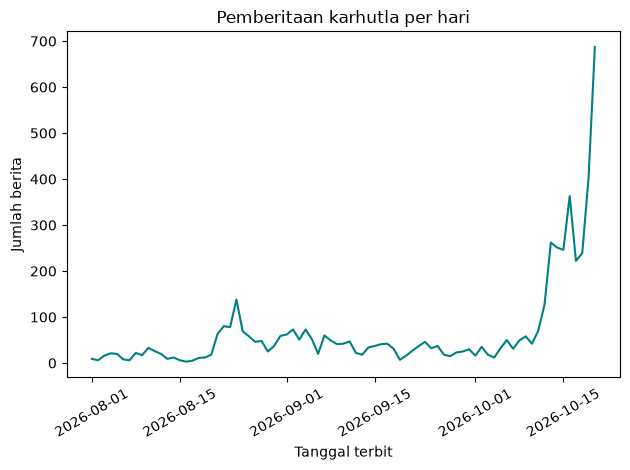

Hari dengan berita terbanyak: 2026-10-20 sebanyak 687 berita


In [ ]:
#tren pemberitaan karhutla
daily = data.groupby(data["publish_date"].dt.date).size()
fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, color="teal")
ax.set(xlabel="Tanggal terbit", ylabel="Jumlah berita", title="Pemberitaan karhutla per hari")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
print("Hari dengan berita terbanyak:", daily.idxmax(), "sebanyak", daily.max(), "berita")

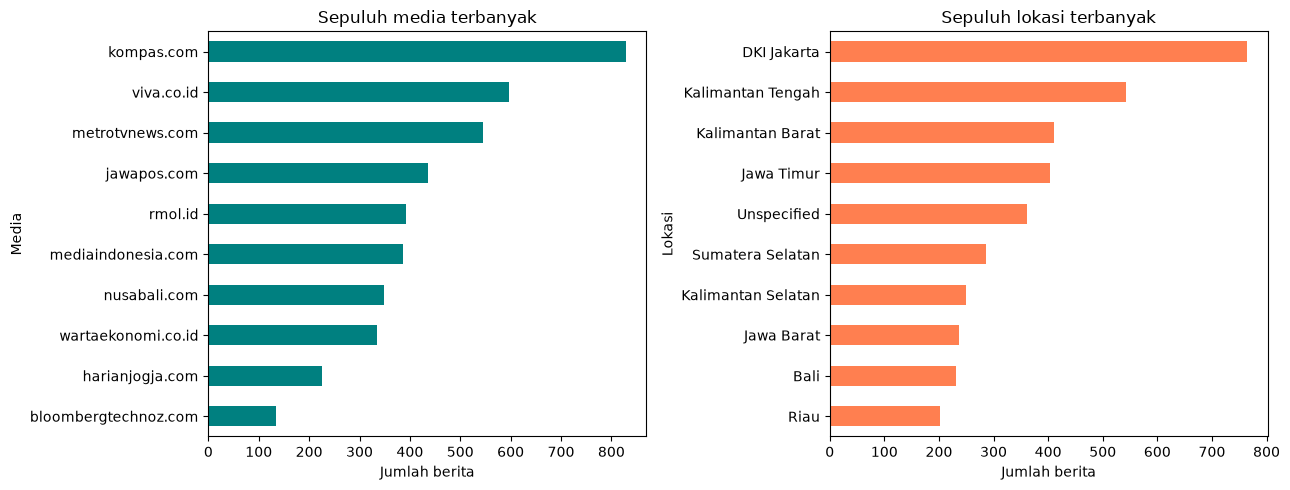

In [ ]:
#artikel berita berdasarkan media dan lokasi
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
data["source_domain"].value_counts().head(10).sort_values().plot.barh(ax=axes[0], color="teal")
data["geo_name"].value_counts().head(10).sort_values().plot.barh(ax=axes[1], color="coral")
axes[0].set(title="Sepuluh media terbanyak", xlabel="Jumlah berita", ylabel="Media")
axes[1].set(title="Sepuluh lokasi terbanyak", xlabel="Jumlah berita", ylabel="Lokasi")
plt.tight_layout()
plt.show()


Berita terbanyak ditemukan pada bulan oktober 2026, khususnya tanggal 2026-10-20 yaitu sebanyak 383 berita.
Kompas merupakan media dengan artikel berita terbanyak, diikuti oleh viva dan metrotv di peringkan kedua dan ketiga.
Berdasarkan lokasi, grafik menampilkan sepuluh lokasi dengan jumlah berita karhutla terbanyak dalam dataset. Tingginya jumlah berita menunjukkan dominasi pemberitaan terkait lokasi tersebut selama periode pengamatan, tetapi belum dapat digunakan untuk menyimpulkan tingkat kejadian, keparahan karhutla, lokasi karhutla, atau sumber asal media, seperti Kompas Jakarta dan Viva Jakarta. Terkait lokasi, perlu ditelaah lebih lanjut.


#### Evaluasi kolom kategori

Data yang dianalisis adalah data yang sudah dibersihkan dan trasnformasi, dari informasi data.info diatas, beberapa kolom penting tidak terlihat yaitu `doc_id`, `title_clean`, dan `relevance_tier` 
Kolom `relevance_tier` sudah tersedia dari tahap sebelumnya yang mengkategorikan sebagai issue 'karhutla'. 

| Kolom | Deskripsi |
| :--- | :--- |
| `core` | Memuat istilah terkait karhutla, seperti kebakaran hutan, kabut asap, atau lahan gambut |
| `generic_fire` | Memuat istilah kebakaran umum tanpa kecocokan dengan istilah karhutla |
| `off_topic` | Tidak memenuhi kedua aturan tersebut |

In [3]:
kolom_pilihan = ['doc_id', 'title_clean', 'relevance_tier']
display(data[kolom_pilihan].head(10))

,doc_id,title_clean,relevance_tier
0,D00005,"Kerja Keras Padamkan Karhutla, BNPB Akan Geber...",core
1,D00006,BRIN Jelaskan Fungsi Pakai Dry Ice Atasi Asap ...,core
2,D00010,Empat Orang Gugur dalam Pemadaman Karhutla Bro...,core
3,D00011,Antisipasi Karhutla Gunung Lawu Menjalar ke Ma...,core
4,D00012,Kematian Sefriel di Karhutla Bromo: Keluarga P...,core
5,D00135,"Titik Panas Jatim Naik 44,7 Persen, Fraksi PDI...",core
6,D00136,BPBD Magetan Dirikan Pos Siaga Karhutla Gunung...,core
7,D00137,"Duka Keluarga Sefriel, Relawan Karhutla Bromo ...",core
8,D00138,Pesan Tokoh Tengger: Menjaga Bromo Tak Seharus...,core
9,D00139,"Karhutla Melanda Arjuno-Welirang, Seluruh Jalu...",core


In [4]:
jumlah_kategori = data['relevance_tier'].value_counts()
display(jumlah_kategori)

nama_kategori = {
    'core': 'Karhutla',
    'generic_fire': 'Kebakaran umum',
    'off_topic': 'Di luar topik',
}
komposisi = jumlah_kategori.rename(index=nama_kategori)
display(komposisi)

relevance_tier
core            4039
generic_fire     931
off_topic        332
Name: count, dtype: int64

relevance_tier
Karhutla          4039
Kebakaran umum     931
Di luar topik      332
Name: count, dtype: int64

In [5]:
#memilih data yang relevan dengan kategori karhutla
kondisi_karhutla = data['relevance_tier'] == 'core'

berita = data[kondisi_karhutla].copy()
berita = berita.reset_index(drop=True)

print('Seluruh artikel bersih:', len(data))
print('Artikel kategori karhutla:', len(berita))
berita[kolom_pilihan].head()

Seluruh artikel bersih: 5302
Artikel kategori karhutla: 4039


,doc_id,title_clean,relevance_tier
0,D00005,"Kerja Keras Padamkan Karhutla, BNPB Akan Geber...",core
1,D00006,BRIN Jelaskan Fungsi Pakai Dry Ice Atasi Asap ...,core
2,D00010,Empat Orang Gugur dalam Pemadaman Karhutla Bro...,core
3,D00011,Antisipasi Karhutla Gunung Lawu Menjalar ke Ma...,core
4,D00012,Kematian Sefriel di Karhutla Bromo: Keluarga P...,core


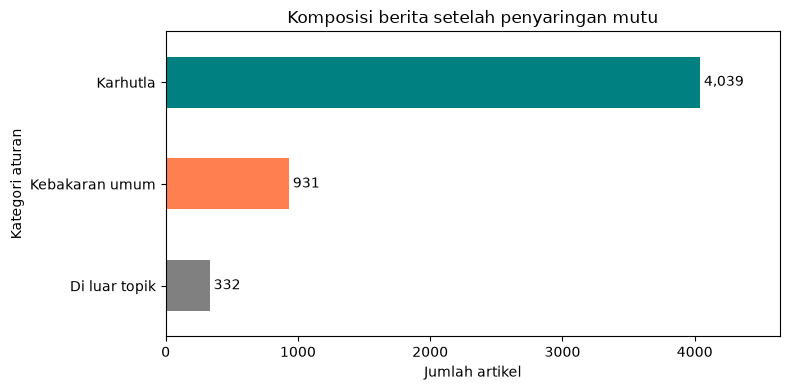

In [6]:
#visualisasi komposisi berita berdsarkan kategori
fig, ax = plt.subplots(figsize=(8, 4))
komposisi.plot.barh(ax=ax, color=['teal', 'coral', 'gray'])
ax.invert_yaxis()
ax.set(title='Komposisi berita setelah penyaringan mutu', xlabel='Jumlah artikel', ylabel='Kategori aturan')
for posisi, jumlah in enumerate(komposisi):
    ax.text(jumlah, posisi, f' {jumlah:,}', va='center')
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

Sebanyak **4.039 dari 5.302 artikel bersih (76,2%)** masuk kategori karhutla, yang selanjutnya akan digunakan untuk pemodelan.

### 3.5 Analisis Kasus
#### Isu Apa yang Muncul dalam Pemberitaan?
Dari total 4.039 artikel yang sama, pengelompokan kata dilakukan dengan *Non-negative Matrix Factorization* (NMF) dengan bobot TF-IDF dan *Latent Dirichlet Allocation* (LDA) dengan frekuensi istilah. Daftar kata umum, batas kosakata, dan jumlah topik kedua metode dibuat sama.

#### Pengelompokan dengan NMF dengan bobot TF-IDF

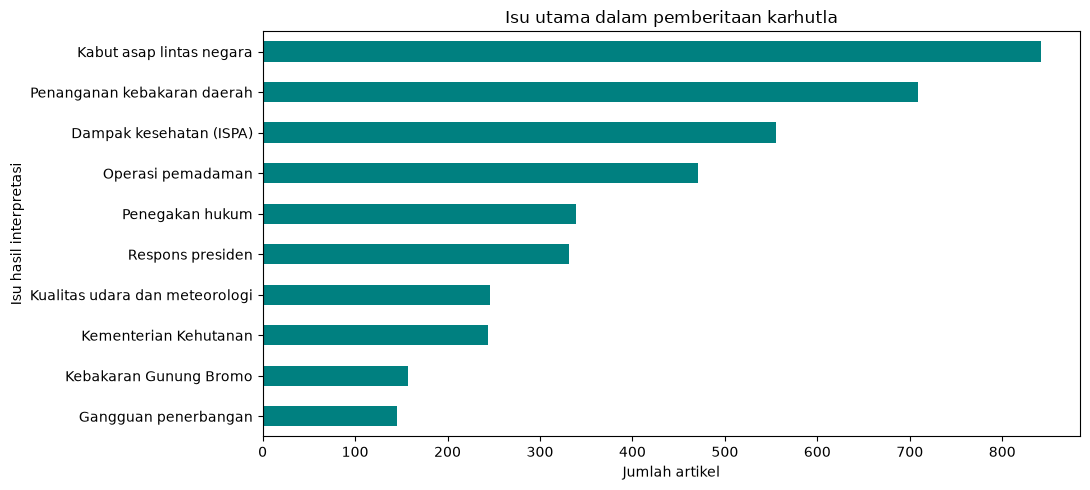

,Isu,Kata pendukung,Contoh judul
0,Kementerian Kehutanan,"raja, raja juli, antoni, menhut, juli, kehutan...",[Kronologi Gubernur Kalbar Emosi sampai Bentak...
1,Dampak kesehatan (ISPA),"kesehatan, anak, pernapasan, asap, paparan, ru...","[Dituding Tone Deaf soal Karhutla, Tasya Faras..."
2,Penanganan kebakaran daerah,"api, petugas, kabupaten, desa, lokasi, kecamat...",[Antisipasi Karhutla Gunung Lawu Menjalar ke M...
3,Operasi pemadaman,"operasi, bnpb, kalimantan, omc, modifikasi, mo...","[Kerja Keras Padamkan Karhutla, BNPB Akan Gebe..."
4,Gangguan penerbangan,"penerbangan, bandara, bandar udara, bandar, ma...",[Kemenhub Catat 2.458 Penerbangan Terdampak Ka...
5,Respons presiden,"dudung, presiden, prabowo, presiden prabowo, s...","[Sentil Raffi Ahmad dan Mulan Jameela, Umi Pip..."
6,Kualitas udara dan meteorologi,"bmkg, sebaran asap, sebaran, atmosfer, kualita...","[Asap Karhutla Menjauh dari Jabodetabek, Tersi..."
7,Penegakan hukum,"tersangka, korporasi, hukum, polda, kasus, pid...","[Update Karhutla: 98 Laporan Naik Penyidikan, ..."
8,Kebakaran Gunung Bromo,"bromo, tnbts, probolinggo, meninggal, korban, ...",[Empat Orang Gugur dalam Pemadaman Karhutla Br...
9,Kabut asap lintas negara,"negara, singapura, malaysia, perusahaan, perso...",[Daniel Mananta Soroti Bencana di Sumatra dan ...


In [ ]:
kata_umum = sorted(set('''
ada adalah adanya adapun agak agar akan akankah akhir akhiri akhirnya aku
antara antaranya apa apapun apabila apakah apalagi apatah arah artinya asal
atas atau ataukah ataupun awal awalnya bagaimana bagaimanakah bagaimanapun
bagi bagian bahkan bahwa baik bakal banyak bapak baru bawah beberapa begini
begitu belakang belum benar berbagai beri berikan berkata berlaku bermaksud
bermula berpendapat berperan bersamaan bertanya berupa besar betul biasa
bilang bila bilakah bisa bisakah boleh buat bukan bukankah bukanlah bukannya
bulan cara caranya cukup cuma
dahulu dalam dan dapat dari daripada datang dekat demi demikian dengan depan
di dia dianggap diantaranya dibuat dicapai dicatat dilakukan dilihat dimaksud
dimana diminta dipakai dipastikan diri dirinya disampaikan disebut disini
disitu ditambahkan ditanya ditanyakan ditegaskan ditujukan dituturkan diucapkan
diulang diumumkan diutarakan diberi diberikan dijelaskan dikatakan diketahui
dilaporkan dimulai diperlukan disebutkan ditetapkan ditolak ditemukan ditangani
ditangkap dituntut divonis dong dua dulu empat enggak entah gagal gimana
hal hampir hanya hanyalah hari harus haruslah harusnya hingga
ia ialah ikut ingin ini inilah itu itulah
jadi jadinya jangan jarang jelas jelaskan jelasnya jika jikalau juga jumlah
jumlahnya justru
kala kalau kalian kami kamu kan kapan karena karenanya kata katakan keadaan
kecil kedua keduanya keluar kembali kemudian kenapa kepada ketika kini kira
kita lagi lah lain lainnya lalu lama lanjut langsung luas luar
maka makin malah mampu mana masih masing mau maupun melainkan melakukan
melalui melihat memang membuat memerlukan memihak meminta memperoleh mendapat
mendapatkan mengakhiri mengapa mengatakan mengenai menggunakan menghendaki
mengingat menginginkan mengira mengetahui mengucapkan mengulang mengurus
menjelaskan menuju menunjuk menunjukkan menuntut menyatakan menyebut
menyebutkan menyiapkan merupakan meski meskipun minta mirip misal misalkan
misalnya mula mulai mungkin namun nanti nyaris oleh olehnya
pada padahal padanya paling panjang para pasti patut pemerintah perlu pernah
pertama pertanyaan pihak pihaknya pukul pula pun punya rasa rata
saat saja saling sama sambil sampai sampaikan sana sangat satu saya se sebab
sebabnya sebagai sebagaimana sebagainya sebanyak sebelum sebelumnya sebenarnya
seberapa sebuah sebut secara sedang sedangkan sedikit segala segera seharusnya
sehingga sejak sejumlah sekali sekaligus sekarang sekitar selama selanjutnya
seluruh semakin semacam semasa semua semuanya sendiri senang
sepanjang seperti sering serta sesuai setelah setempat setiap sudah supaya
tadi tahu tahun tak tambah tampak tandas tanpa tanya tapi tegas telah tempat
terjadi terhadap termasuk ternyata tertentu tetapi tiap tolong
ucap ujar umum ungkap untuk usai wah waktu walau walaupun
yaitu yakin yakni yang
kompas com detik liputan6 cnbc antara republika tribun sindonews okezone
kumparan tempo katadata mongabay bisnis viva jawapos metrotvnews rmol
wartaekonomi mediaindonesia harianjogja bloombergtechnoz nusabali kontan
suara merdeka pikiran rakyat jpnn inilah idntimes kbr gadis grid
baca juga advertisement gulir lanjut scroll resume content copyright
foto video ilustrasi dokumentasi grafis infografis indeks berita
wib selasa senin rabu kamis jumat sabtu minggu
jakarta indonesia republika co
kata ujar jelas tegas ungkap sebut tambah terang
orang tahun hari bulan kali ke lebih terus
'''.split()))

tfidf = TfidfVectorizer(stop_words=kata_umum, min_df=3, max_df=0.6, ngram_range=(1, 2), max_features=20000, sublinear_tf=True)
matriks = tfidf.fit_transform(berita['content_clean'])
nmf = NMF(n_components=10, init='nndsvda', random_state=RANDOM_STATE, max_iter=400)
bobot_topik = nmf.fit_transform(matriks)
istilah = tfidf.get_feature_names_out()
kata_topik = {nomor: istilah[bobot.argsort()[::-1][:8]].tolist() for nomor, bobot in enumerate(nmf.components_)}

nama_isu = {
    0: 'Kementerian Kehutanan',
    1: 'Dampak kesehatan (ISPA)',
    2: 'Penanganan kebakaran daerah',
    3: 'Operasi pemadaman',
    4: 'Gangguan penerbangan',
    5: 'Respons presiden',
    6: 'Kualitas udara dan meteorologi',
    7: 'Penegakan hukum',
    8: 'Kebakaran Gunung Bromo',
    9: 'Kabut asap lintas negara',
    -1: 'Belum terpetakan',
}
berita['topik_nmf'] = bobot_topik.argmax(axis=1)
berita.loc[bobot_topik.sum(axis=1) == 0, 'topik_nmf'] = -1
berita['isu'] = berita['topik_nmf'].map(nama_isu)
ukuran_isu = berita['isu'].value_counts()

fig, ax = plt.subplots(figsize=(11, 5))
ukuran_isu.sort_values().plot.barh(ax=ax, color='teal')
ax.set(title='Isu utama dalam pemberitaan karhutla', xlabel='Jumlah artikel', ylabel='Isu hasil interpretasi')
plt.tight_layout()
plt.show()

contoh_isu = pd.DataFrame([
    {'Isu': nama_isu[nomor], 'Kata pendukung': ', '.join(kata),
     'Contoh judul': berita.loc[berita['topik_nmf'].eq(nomor), 'title_clean'].head(2).to_list()}
    for nomor, kata in kata_topik.items()
])
display(contoh_isu)

Tiga kelompok terbesar dalam NMF berlabel **kabut asap lintas negara (842 artikel)**, **penanganan kebakaran daerah (709 artikel)**, dan **dampak kesehatan (555 artikel)**.

Label tersebut belum mencakup seluruh isi kelompok. Kelompok kabut asap lintas negara, misalnya, juga memuat pembahasan politik sehingga memerlukan pemeriksaan artikel lebih lanjut.

#### Pengelompokan dengan LDA

LDA memperkirakan proporsi sepuluh topik dalam setiap artikel berdasarkan frekuensi istilah. Hasilnya digunakan untuk membandingkan pengelompokan isu dengan NMF.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

penghitung_kata = CountVectorizer(
    stop_words=kata_umum,
    min_df=3,
    max_df=0.6,
    ngram_range=(1, 2),
    max_features=20000,
)
matriks_hitung = penghitung_kata.fit_transform(berita['content_clean'])
istilah_lda = penghitung_kata.get_feature_names_out()

lda = LatentDirichletAllocation(
    n_components=10,
    learning_method='batch',
    max_iter=10,
    random_state=RANDOM_STATE,
)
proporsi_lda = lda.fit_transform(matriks_hitung)
berita['topik_lda'] = proporsi_lda.argmax(axis=1)

kata_topik_lda = {}
for nomor, bobot in enumerate(lda.components_):
    urutan_kata = bobot.argsort()[::-1][:8]
    kata_topik_lda[nomor] = istilah_lda[urutan_kata].tolist()

ringkasan_lda = []
for nomor, kata in kata_topik_lda.items():
    kondisi_topik = berita['topik_lda'] == nomor
    ringkasan_lda.append({
        'Topik LDA': nomor,
        'Jumlah artikel': int(kondisi_topik.sum()),
        'Kata utama': ', '.join(kata),
        'Contoh judul': berita.loc[kondisi_topik, 'title_clean'].head(2).tolist(),
    })

ringkasan_lda = pd.DataFrame(ringkasan_lda)
with pd.option_context('display.max_colwidth', None):
    display(ringkasan_lda)

,Topik LDA,Jumlah artikel,Kata utama,Contoh judul
0,0,232,"bencana, prabowo, presiden, sekolah, presiden prabowo, nasional, bnpb, kepala","[Dua Tahun Prabowo-Gibran, PDIP Sebut Jokowi dan Gibran Jadi Beban Pemerintahan, Kritik Pedas Pendukung Garis Kerasnya di 2 Tahun Prabowo: Rupiah Tembus 18 Ribu, MBG Banyak Masalah]"
1,1,208,"penerbangan, bandara, udara, tersangka, bandar, bandar udara, polda, asap","[Update Karhutla: 98 Laporan Naik Penyidikan, Ada Pihak Asing, Kemenhub Catat 2.458 Penerbangan Terdampak Karhutla]"
2,2,591,"api, kawasan, petugas, kabupaten, gunung, titik, lokasi, 10","[Antisipasi Karhutla Gunung Lawu Menjalar ke Magetan, Perhutani Bangun Ilaran Hampir 3,5 Kilometer, BPBD Magetan Dirikan Pos Siaga Karhutla Gunung Lawu, Antisipasi Api Merambat ke Jawa Timur]"
3,3,281,"gambut, air, api, musim, kawasan, sumber, kemarau, el","[BRIN Jelaskan Fungsi Pakai Dry Ice Atasi Asap Karhutla, Pabrik Wilmar (CEKA) di Pontianak Terdampak Asap Karhutla]"
4,4,553,"pemadaman, operasi, negara, penanganan karhutla, bantuan, presiden, menteri, kalimantan","[Jepang Turun Tangan, 3 Helikopter Chinook Dikirim ke Kalimantan Bantu Hadapi Karhutla, Alasan Pemerintah Belum Jadikan Karhutla Sebagai Bencana Nasional]"
5,5,510,"titik, kalimantan, selatan, hujan, barat, udara, kabupaten, hektare","[Kerja Keras Padamkan Karhutla, BNPB Akan Geber Modifikasi Cuaca, Titik Panas Jatim Naik 44,7 Persen, Fraksi PDIP Desak Pemprov Perkuat Antisipasi Karhutla]"
6,6,505,"perusahaan, hukum, lingkungan, negara, penegakan, penegakan hukum, singapura, korporasi","[Kematian Sefriel di Karhutla Bromo: Keluarga Pertanyakan Penugasan dan Keselamatan, Tak Takut Diserang Buzzer, Jerome Polin Ungkap Alasannya Gencar Suarakan Karhutla Kalimantan: Ayo Teman-Teman Speak Up]"
7,7,241,"kawasan, satwa, orangutan, api, tim, lokasi, taman, kalimantan","[Empat Orang Gugur dalam Pemadaman Karhutla Bromo, Khofifah Berduka, Kronologi Orang Utan Ditemukan Pingsan di Kebun Sawit Ketapang Kalbar, Diduga karena Asap Karhutla Kalimantan]"
8,8,316,"pencegahan, daerah, asap, langkah, kalimantan, penanganan karhutla, memastikan, bersama","[Uji Kompetensi Wartawan di Palembang: Jurnalis Dituntut Kawal Transparansi Penanganan Karhutla, Asap Karhutla dan Hilangnya Mata Pencaharian, DPR Desak Pemerintah Bertindak]"
9,9,602,"asap, kesehatan, udara, kabut, kabut asap, anak, kualitas, kualitas udara","[Sentil Raffi Ahmad dan Mulan Jameela, Umi Pipik Minta Para Wakil Rakyat Sampaikan Kondisi Karhutla ke Presiden Prabowo: Tolong!, Profil Muhidin, Gubernur Kalimantan Selatan yang Sebut Kondisi Karhutla Tidak Parah, Kini Minta Maaf ke Publik]"


#### Perbandingan Kelompok Topik

Nama topik LDA berdasarkan pada kata utama dan contoh judul. Beberapa kelompok masih memuat isu berbeda, seperti penerbangan dan penyidikan. Adapun grafik berikut menghitung artikel berdasarkan topik dengan proporsi terbesar.
Nomor topik tidak menunjukkan pasangan antarmetode: topik 0 pada NMF dapat berbeda isi dengan topik 0 pada LDA. Perbandingan perlu mengacu pada kata utama dan isi artikel.

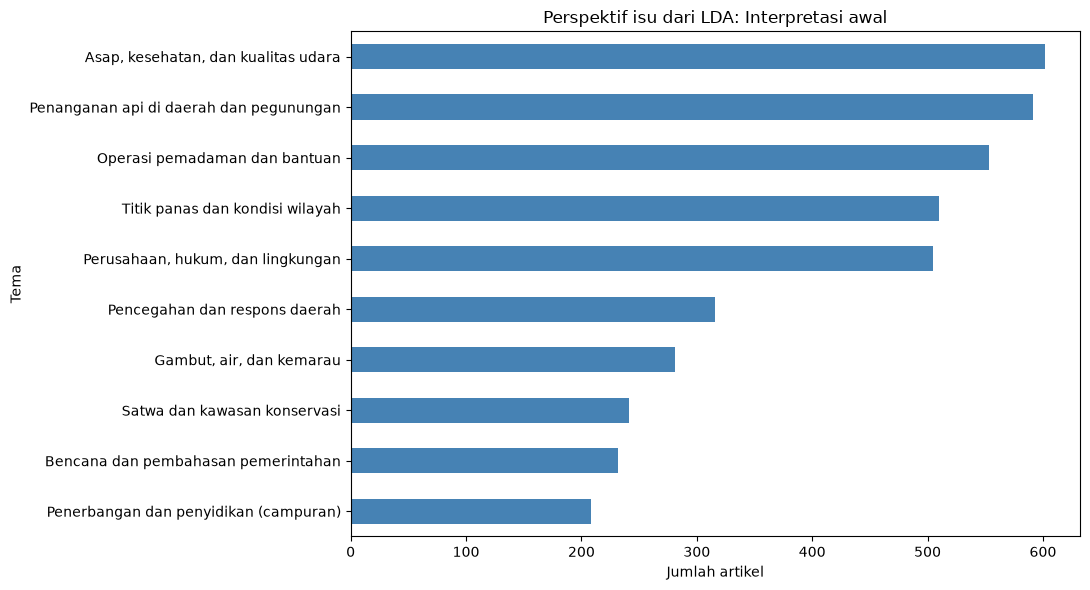

In [ ]:
#pengelompokan topik LDA berdasarkan pada kata utama dan contoh judul
nama_isu_lda = {
    0: 'Bencana dan pembahasan pemerintahan',
    1: 'Penerbangan dan penyidikan (campuran)',
    2: 'Penanganan api di daerah dan pegunungan',
    3: 'Gambut, air, dan kemarau',
    4: 'Operasi pemadaman dan bantuan',
    5: 'Titik panas dan kondisi wilayah',
    6: 'Perusahaan, hukum, dan lingkungan',
    7: 'Satwa dan kawasan konservasi',
    8: 'Pencegahan dan respons daerah',
    9: 'Asap, kesehatan, dan kualitas udara',
}
berita['isu_lda'] = berita['topik_lda'].map(nama_isu_lda)
ukuran_isu_lda = berita['isu_lda'].value_counts()

fig, ax = plt.subplots(figsize=(11, 6))
ukuran_isu_lda.sort_values().plot.barh(ax=ax, color='steelblue')
ax.set(title='Perspektif isu dari LDA: Interpretasi awal', xlabel='Jumlah artikel', ylabel='Tema')
plt.tight_layout()
plt.show()

Pada LDA, kelompok terbesar berlabel **asap, kesehatan, dan kualitas udara sebanyak 602 artikel**. Kelompok lain mencakup **gambut, air, dan kemarau (281 artikel)** serta **satwa dan kawasan konservasi (241 artikel)**.

NMF dan LDA sama-sama mengelompokkan pemberitaan tentang kesehatan dan penanganan kebakaran, tetapi susunan anggotanya berbeda. Perbedaan ini memberi pilihan artikel untuk ditelaah lebih lanjut, tanpa menunjukkan metode mana yang lebih akurat.

Adapun Sawit yang ramai di sosial media, belum tercantum sebagai nama topik tersendiri. Bagian berikut menelusuri penyebutannya pada judul dan isi artikel untuk mengetahui sebarannya dalam hasil kedua model.

### Penelusuran Lanjutan: Penyebutan Kata Sawit

Untuk memeriksa keberadaan sawit di luar nama tersebut, kita mencari kata `sawit` dan frasa `palm oil` pada judul atau isi artikel tanpa melatih ulang model.

Pencarian kata `sawit` juga mencakup frasa kelapa sawit dan minyak sawit. Setiap artikel dihitung sekali, terlepas berapa pun jumlah penyebutannya. Artikel yang hanya memuat nama perusahaan atau singkatan komoditas tanpa kedua istilah tersebut tidak tercakup.

,Jumlah artikel
Menyebut pada judul,56
Menyebut pada isi,274
"Judul atau isi, tanpa hitung ganda",277


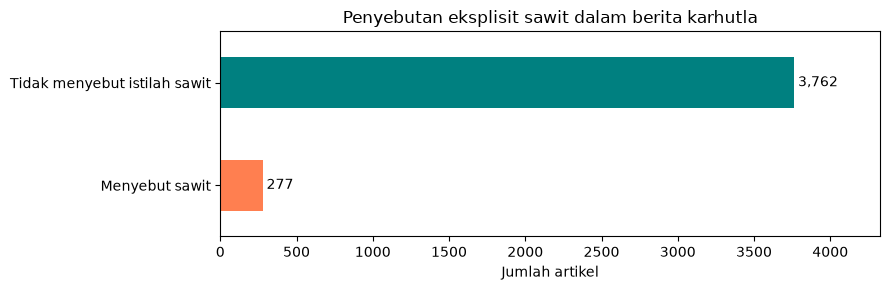

In [ ]:
pola_sawit = r'\bsawit\b|\bpalm oil\b'
judul_sawit = berita['title_clean'].str.contains(pola_sawit, case=False, regex=True)
isi_sawit = berita['content_clean'].str.contains(pola_sawit, case=False, regex=True)
berita['menyebut_sawit'] = judul_sawit | isi_sawit
artikel_sawit = berita[berita['menyebut_sawit']].copy()

ringkasan_sawit = pd.Series({
    'Menyebut pada judul': int(judul_sawit.sum()),
    'Menyebut pada isi': int(isi_sawit.sum()),
    'Judul atau isi, tanpa hitung ganda': len(artikel_sawit),
})
display(ringkasan_sawit.to_frame('Jumlah artikel'))

jumlah_sawit = pd.Series({
    'Menyebut sawit': len(artikel_sawit),
    'Tidak menyebut istilah sawit': len(berita) - len(artikel_sawit),
})
fig, ax = plt.subplots(figsize=(9, 3))
jumlah_sawit.plot.barh(ax=ax, color=['coral', 'teal'])
ax.set(title='Penyebutan eksplisit sawit dalam berita karhutla', xlabel='Jumlah artikel', ylabel='')
for posisi, jumlah in enumerate(jumlah_sawit):
    ax.text(jumlah, posisi, f' {jumlah:,}', va='center')
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

Sebanyak **277 dari 4.039 artikel (6,9%)** menyebut sawit: 56 artikel pada judul dan 274 pada isi. Sebagian artikel menyebutnya pada kedua bagian sehingga angka 56 dan 274 tidak dapat dijumlahkan.
Penyebutan ini belum menunjukkan apakah sawit menjadi fokus utama artikel atau berkaitan dengan penyebab kebakaran.

### Sebaran Artikel yang Menyebut Sawit

Topik utama dari 277 artikel ditelusuri menurut hasil NMF dan LDA, grafik berikut menggunakan pengelompokan yang sudah ada.

Tabel berikut menampilkan jumlah artikel yang menyebut sawit serta persentasenya terhadap seluruh artikel dalam setiap topik. Jumlah menunjukkan banyaknya artikel, sedangkan persentase menunjukkan porsi penyebutan sawit dalam kelompok.

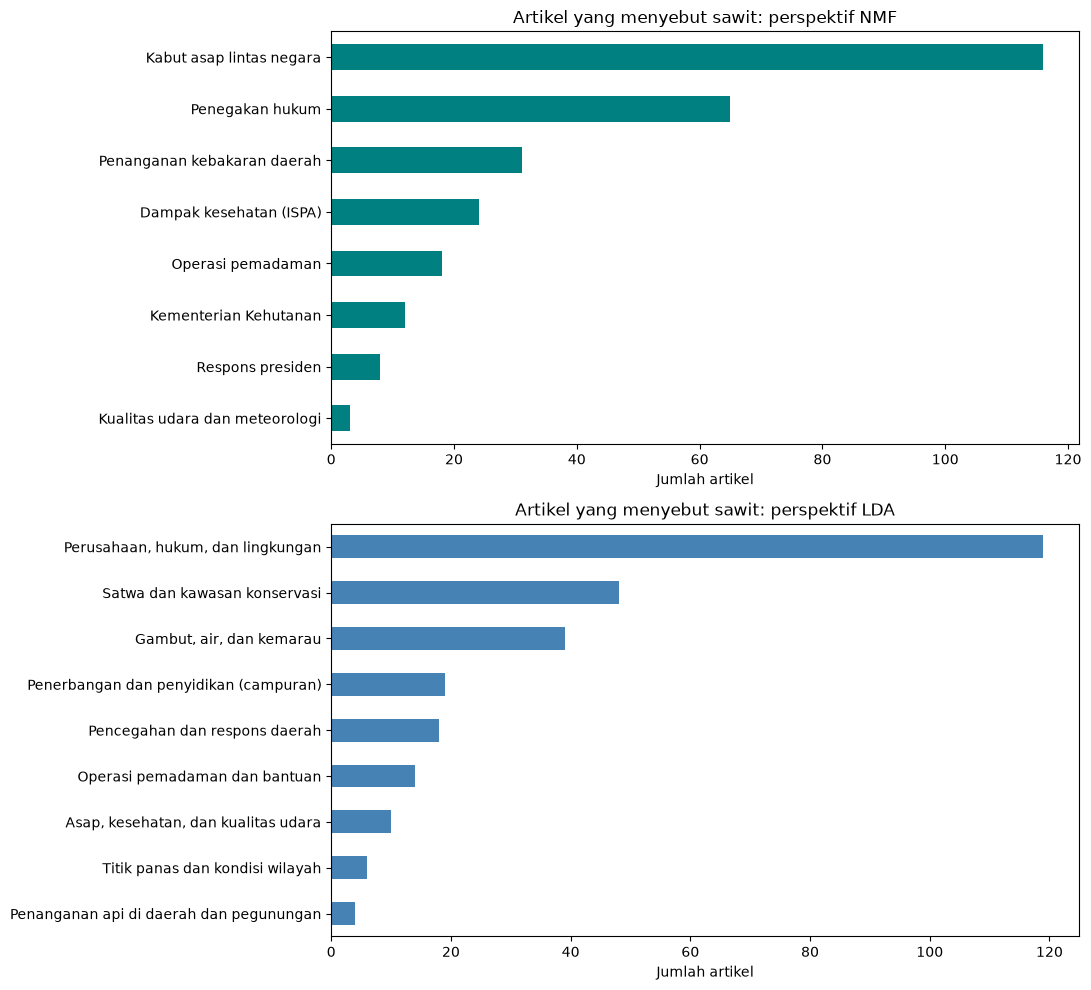

,Artikel sawit,Seluruh artikel topik,Persen dalam topik
isu,,,
Kabut asap lintas negara,116,842,13.8
Penegakan hukum,65,339,19.2
Penanganan kebakaran daerah,31,709,4.4
Dampak kesehatan (ISPA),24,555,4.3
Operasi pemadaman,18,471,3.8
Kementerian Kehutanan,12,244,4.9
Respons presiden,8,331,2.4
Kualitas udara dan meteorologi,3,246,1.2


,Artikel sawit,Seluruh artikel topik,Persen dalam topik
isu_lda,,,
"Perusahaan, hukum, dan lingkungan",119,505,23.6
Satwa dan kawasan konservasi,48,241,19.9
"Gambut, air, dan kemarau",39,281,13.9
Penerbangan dan penyidikan (campuran),19,208,9.1
Pencegahan dan respons daerah,18,316,5.7
Operasi pemadaman dan bantuan,14,553,2.5
"Asap, kesehatan, dan kualitas udara",10,602,1.7
Titik panas dan kondisi wilayah,6,510,1.2
Penanganan api di daerah dan pegunungan,4,591,0.7


In [ ]:
sebaran_sawit_nmf = artikel_sawit['isu'].value_counts()
sebaran_sawit_lda = artikel_sawit['isu_lda'].value_counts()

fig, axes = plt.subplots(2, 1, figsize=(11, 10))
sebaran_sawit_nmf.sort_values().plot.barh(ax=axes[0], color='teal')
sebaran_sawit_lda.sort_values().plot.barh(ax=axes[1], color='steelblue')
axes[0].set(title='Artikel yang menyebut sawit: perspektif NMF', xlabel='Jumlah artikel', ylabel='')
axes[1].set(title='Artikel yang menyebut sawit: perspektif LDA', xlabel='Jumlah artikel', ylabel='')
plt.tight_layout()
plt.show()

rincian_nmf = pd.DataFrame({'Artikel sawit': sebaran_sawit_nmf})
rincian_nmf['Seluruh artikel topik'] = ukuran_isu
rincian_nmf['Persen dalam topik'] = (100 * rincian_nmf['Artikel sawit'] / rincian_nmf['Seluruh artikel topik']).round(1)

display(rincian_nmf)

rincian_lda = pd.DataFrame({'Artikel sawit': sebaran_sawit_lda})
rincian_lda['Seluruh artikel topik'] = ukuran_isu_lda
rincian_lda['Persen dalam topik'] = (100 * rincian_lda['Artikel sawit'] / rincian_lda['Seluruh artikel topik']).round(1)


display(rincian_lda)

Dalam NMF, artikel yang menyebut sawit paling banyak masuk kelompok **kabut asap lintas negara (116 artikel)** dan **penegakan hukum (65 artikel)**. Dalam LDA, jumlah terbanyak berada pada kelompok **perusahaan, hukum, dan lingkungan (119 artikel)**, diikuti **satwa dan kawasan konservasi (48 artikel)** serta **gambut, air, dan kemarau (39 artikel)**.

Sebanyak **23,6%** artikel dalam kelompok perusahaan, hukum, dan lingkungan menyebut sawit. Penyebut persentase ini adalah seluruh artikel dalam topik tersebut, bukan 277 artikel yang menyebut sawit.
Penyebutan sawit tersebar pada beberapa topik. Namun, label kelompok belum cukup untuk menentukan konteks setiap artikel, dimana 119 artikel dalam kelompok perusahaan, hukum, dan lingkungan belum tentu seluruhnya membahas dugaan pelanggaran.

### Konteks Sawit dalam Berita

Empat artikel berikut dipilih untuk memperlihatkan variasi konteks. Kolom `doc_id` menunjukkan identitas artikel dalam CSV. Contoh ini bukan sampel acak dan tidak mewakili proporsi setiap jenis pemberitaan.

Tabel menampilkan potongan teks di sekitar istilah sawit.

In [ ]:
id_contoh_sawit = ['D00229', 'D00206', 'D00226', 'D00164']
contoh_sawit = artikel_sawit[artikel_sawit['doc_id'].isin(id_contoh_sawit)].copy()
pola_potongan = r'(?is)(.{0,100}(?:\bsawit\b|\bpalm oil\b).{0,220})'
contoh_sawit['potongan_isi'] = contoh_sawit['content_clean'].str.extract(pola_potongan, expand=False)
contoh_sawit['potongan_isi'] = contoh_sawit['potongan_isi'].fillna('Istilah hanya ditemukan pada judul; periksa isi lengkap.')

kolom_sawit = ['doc_id', 'title_clean', 'source_domain', 'potongan_isi', 'link']
with pd.option_context('display.max_colwidth', None):
    display(contoh_sawit[kolom_sawit])

,doc_id,title_clean,source_domain,potongan_isi,link
29,D00164,"Kronologi Orang Utan Ditemukan Pingsan di Kebun Sawit Ketapang Kalbar, Diduga karena Asap Karhutla Kalimantan",grid.id,Grid.ID - Kronologi orang utan ditemukan pingsan di kebun sawit Ketapang Kalbar. Diduga karena asap karhutla (kebakaran hutan dan lahan) Kalimantan. Warga menemukan seekor orang utan jantan dewasa dalam kondisi lemas dan tidak sadarkan diri di sekitar perkebunan sawit milik warga di,https://www.grid.id/read/044409034/kronologi-orang-utan-ditemukan-pingsan-di-kebun-sawit-ketapang-kalbar-diduga-karena-asap-karhutla-kalimantan
63,D00206,Eks Mendag Lutfi Ingatkan Singapura soal Sawit di Karhutla,bloombergtechnoz.com,Istilah hanya ditemukan pada judul; periksa isi lengkap.,https://www.bloombergtechnoz.com/detail-news/125157/eks-mendag-lutfi-ingatkan-singapura-soal-sawit-di-karhutla
81,D00226,Pabrik Wilmar (CEKA) di Pontianak Terdampak Asap Karhutla,bloombergtechnoz.com,si distribusi utama untuk pengiriman bahan baku CPO dan Palm Kernel dari pemasok atau pabrik kelapa sawit. Sunga itu juga menjadi jalur sarana transportasi untuk pengiriman produk-produk hasil pengolahan pabrik kepada distributor atau konsumen.“Asap yang ada di udara sekitar area pabrik akibat dari Karhutla juga berdampak p,https://www.bloombergtechnoz.com/detail-news/124603/pabrik-wilmar-ceka-di-pontianak-terdampak-asap-karhutla
84,D00229,Polri Tetapkan 9 Perusahaan Sawit Jadi Tersangka Karhutla,bloombergtechnoz.com,"berg Meski begitu, Kepolisian belum merinci dengan jelas nama ataupun identitas sembilan perusahaan sawit yang jadi tersangka tersebut. Sementara itu, 223 orang tersangka perorangan telah diamankan dalam kasus karhutla di wilayah Kalimantan dan Sumatra hingga Selasa, 13 Oktober 2026, dari total 273 laporan polisi. “Penegakk",https://www.bloombergtechnoz.com/detail-news/124627/polri-tetapkan-9-perusahaan-sawit-jadi-tersangka-karhutla


Keempat contoh memuat konteks yang berbeda:

| Artikel | Konteks pemberitaan | Hal yang perlu diperiksa |
| :--- | :--- | :--- |
| `D00229` | Penetapan perusahaan sawit sebagai tersangka | Sumber pernyataan, status perkara, dan tanggapan pihak terkait. Status tersangka tidak sama dengan putusan bersalah. |
| `D00226` | Dampak asap terhadap pabrik pengolahan sawit | Bentuk gangguan operasional dan sumber keterangannya. |
| `D00164` | Penemuan satwa di sekitar kebun sawit dengan dugaan dampak asap | Dasar dugaan dan konteks lokasi. Lokasi penemuan tidak membuktikan penyebab kebakaran. |
| `D00206` | Penyebutan sawit dan Singapura pada judul | Istilah sawit tidak ditemukan dalam isi bersih. Periksa artikel sumber sebelum menafsirkan kaitannya. |

Penandaan konteks belum mencakup seluruh 277 artikel, sehingga kajian ini belum menentukan jenis pemberitaan yang dominan.

Untuk analisis lanjutan, pilih sampel lintas media dan catat fokus artikel, narasumber, dasar pernyataan, serta tanggapan perusahaan. Bedakan dugaan tanggung jawab, dampak terhadap usaha, dan konteks lingkungan. Satu artikel dapat memuat lebih dari satu konteks.

## 4. Kesimpulan

Pemodelan terhadap **4.039 artikel kategori karhutla** menghasilkan kelompok pemberitaan tentang kesehatan, penanganan kebakaran, hukum, dan lingkungan. Dalam NMF, kelompok terbesar berlabel **kabut asap lintas negara (842 artikel)**. Dalam LDA, kelompok terbesar berlabel **asap, kesehatan, dan kualitas udara (602 artikel)**. Perbedaan pengelompokan membantu menentukan artikel yang perlu ditelaah lebih lanjut, dan tidak membuktikan keunggulan salah satu metode. 

Penelusuran lanjutan menemukan **277 artikel (6,9%)** yang menyebut sawit pada judul atau isi meskipun sawit tidak tercantum sebagai nama topik tersendiri. Penyebutannya tersebar pada beberapa kelompok. Pemeriksaan empat contoh memperlihatkan konteks dugaan tanggung jawab, dampak usaha, dan lingkungan, tetapi belum cukup untuk menentukan kecenderungan seluruh pemberitaan sawit.

Hasil kajian dapat digunakan untuk memilih artikel yang perlu diperiksa secara manual, terutama pada kelompok dengan isu campuran. Cakupannya terbatas pada isi berita dimana hasil ini tidak mengukur sentimen masyarakat, percakapan media sosial, keparahan kebakaran, atau membuktikan tanggung jawab pihak tertentu.